# Exercice 1 : Lire un journal, trouver l'attaque

> **En une phrase :** les outils de détection ne voient que des **journaux** (logs). On ouvre un vrai journal de serveur et on y cherche, à la main, les traces d'une attaque.

**Le scénario.** Vous êtes analyste de niveau 1. Un serveur Linux est joignable en SSH depuis Internet. On vous donne **2 000 lignes** de son journal, soit une matinée. Y a-t-il eu une attaque ? Par qui ? Contre quel compte ? A-t-elle réussi ?

**La source.** *Loghub* (projet de recherche, Université chinoise de Hong Kong) : de vrais journaux, publiés pour la recherche. Ici, le journal `sshd` d'un serveur de laboratoire nommé **LabSZ**, laissé ouvert sur Internet.

**Le plan.**
1. Lire le journal brut.
2. Le ranger dans un tableau.
3. Qui attaque ? (les adresses IP)
4. Quels comptes sont visés ?
5. Quand ? (la chronologie)
6. Une connexion a réussi : est-ce l'attaquant ?

## Étape 0 : exécutez cette cellule en premier
Le notebook est **autonome** : il fonctionne tel quel sur Colab (ouvert depuis Drive) ou en local. Elle doit afficher **Prêt**.

In [1]:
import re, requests
import pandas as pd

URL_SSH = "https://raw.githubusercontent.com/logpai/loghub/master/OpenSSH/OpenSSH_2k.log"

def charger_ssh():
    """Télécharge le journal SSH et le range dans un tableau : une ligne = un événement."""
    lignes = requests.get(URL_SSH, timeout=30).text.splitlines()
    motif = re.compile(r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (.*)$")
    evenements = []
    for ligne in lignes:
        m = motif.match(ligne)
        if m:
            ip = re.search(r"\d+\.\d+\.\d+\.\d+", m.group(2))
            evenements.append({"heure": pd.to_datetime("2016 " + m.group(1), format="%Y %b %d %H:%M:%S"),  # l'année n'est pas écrite dans le journal
                               "message": m.group(2),
                               "ip": ip.group() if ip else None})
    return pd.DataFrame(evenements), lignes

evenements, lignes = charger_ssh()
print('Prêt')

Prêt


## Étape 1 : Lire le journal brut
**Ce qu'on fait :** on affiche les premières lignes, exactement comme elles arrivent dans un SIEM.

In [2]:
print(len(lignes), "lignes\n")
for ligne in lignes[:8]:
    print(ligne)

2000 lignes

Dec 10 06:55:46 LabSZ sshd[24200]: reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN ATTEMPT!
Dec 10 06:55:46 LabSZ sshd[24200]: Invalid user webmaster from 173.234.31.186
Dec 10 06:55:46 LabSZ sshd[24200]: input_userauth_request: invalid user webmaster [preauth]
Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): check pass; user unknown
Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=173.234.31.186 
Dec 10 06:55:48 LabSZ sshd[24200]: Failed password for invalid user webmaster from 173.234.31.186 port 38926 ssh2
Dec 10 06:55:48 LabSZ sshd[24200]: Connection closed by 173.234.31.186 [preauth]
Dec 10 07:02:47 LabSZ sshd[24203]: Connection closed by 212.47.254.145 [preauth]


**👀 Ce qu'on doit voir :** **2 000 lignes**. Chaque ligne = date, machine (`LabSZ`), programme (`sshd`), message. Dès la 1re seconde : `POSSIBLE BREAK-IN ATTEMPT!`, puis `Invalid user webmaster from 173.234.31.186` : quelqu'un essaie un compte qui n'existe pas.

## Étape 2 : Ranger le journal dans un tableau
**Ce qu'on fait :** on classe chaque message dans une **catégorie**. C'est le travail que fait un SIEM à l'arrivée de chaque log (on parle de *normalisation*).

In [3]:
def categorie(message):
    if message.startswith("Failed password"):   return "échec de mot de passe"
    if message.startswith("Invalid user"):      return "compte inexistant"
    if message.startswith("Accepted"):          return "connexion RÉUSSIE"
    if "BREAK-IN" in message:                   return "nom DNS incohérent"
    if "disconnect" in message.lower() or "closed" in message: return "déconnexion"
    return "autre (détails techniques)"

evenements["catégorie"] = evenements["message"].apply(categorie)
print("Du", evenements["heure"].min().time(), "au", evenements["heure"].max().time())
evenements["catégorie"].value_counts()

Du 06:55:46 au 11:04:45


catégorie
autre (détails techniques)    777
échec de mot de passe         518
déconnexion                   506
compte inexistant             113
nom DNS incohérent             85
connexion RÉUSSIE               1
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** environ **4 heures** de journal (06:55 → 11:04). **518 échecs de mot de passe**, **113** tentatives sur des comptes inexistants, et **une seule connexion réussie**.

## Étape 3 : Qui attaque ?
**Ce qu'on fait :** on compte les échecs de mot de passe **par adresse IP**.

In [4]:
echecs = evenements[evenements["catégorie"] == "échec de mot de passe"]
print(len(echecs), "échecs venant de", echecs["ip"].nunique(), "adresses IP différentes\n")
echecs["ip"].value_counts().head(8)

518 échecs venant de 23 adresses IP différentes



ip
183.62.140.253     286
187.141.143.180     80
103.99.0.122        46
112.95.230.3        26
5.188.10.180        18
185.190.58.151      17
123.235.32.19        7
119.4.203.64         6
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** 518 échecs venant de **23 IP**. Une seule, **183.62.140.253**, en fait **286**, plus de la moitié. Puis 187.141.143.180 (80) et 103.99.0.122 (46).

## Étape 4 : Quels comptes sont visés ?
**Ce qu'on fait :** on extrait le nom d'utilisateur essayé dans chaque échec.

In [5]:
comptes = echecs["message"].str.extract(r"Failed password for (?:invalid user )?(\S+) from")[0].rename("compte essayé")
comptes.value_counts().head(10)

compte essayé
root       368
admin       44
oracle       6
support      6
uucp         5
test         5
user         4
git          3
ftp          3
inspur       3
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** **root : 368** fois (71 %). Puis admin (44), oracle, support, test, user, git, ftp… Ce sont les noms par défaut de logiciels connus : c'est une **attaque par dictionnaire** (Ch. 3), pas quelqu'un qui vise ce laboratoire en particulier.

**❓ Question pour la classe :** pourquoi « root » à 71 % ?

*Réponse : c'est le seul compte qui existe sur **toutes** les machines Linux, et il a tous les droits. L'attaquant n'a donc qu'à deviner le mot de passe, pas le nom. D'où la contre-mesure classique : interdire la connexion SSH directe en root (`PermitRootLogin no`).*

## Étape 5 : Quand ? La chronologie
**Ce qu'on fait :** on compte les échecs **par minute** et on trace la courbe.

Maximum : 31 échecs en une minute, à 11:00:00


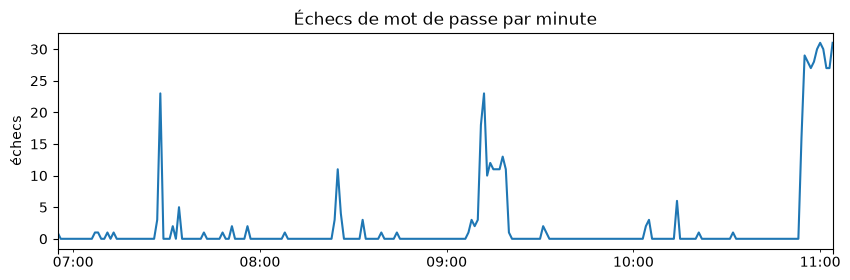

In [6]:
par_minute = echecs.set_index("heure").resample("1min").size()
par_minute.plot(figsize=(10, 2.8), title="Échecs de mot de passe par minute", xlabel="", ylabel="échecs");
print("Maximum :", par_minute.max(), "échecs en une minute, à", par_minute.idxmax().time())

**👀 Ce qu'on doit voir :** des rafales courtes, puis une grosse vague à la fin (10:54 → 11:04) qui monte à **≈ 30 échecs par minute**, soit **un essai toutes les 2 secondes**. Aucun humain ne tape aussi vite : c'est un **script**.

## Étape 6 : Une connexion a réussi. Est-ce l'attaquant ?
**Ce qu'on fait :** on affiche la seule connexion réussie, puis **tout** ce qu'on sait de son adresse IP.

In [7]:
reussie = evenements[evenements["catégorie"] == "connexion RÉUSSIE"].iloc[0]
print(reussie["heure"].time(), reussie["message"], "\n")

historique = evenements[evenements["ip"] == reussie["ip"]]
print("Tout ce qu'a fait", reussie["ip"], ":")
for _, e in historique.iterrows():
    print(" ", e["heure"].time(), e["message"])
print("\nÉchecs avant la réussite :", (historique["catégorie"] == "échec de mot de passe").sum())

09:32:20 Accepted password for fztu from 119.137.62.142 port 49116 ssh2 

Tout ce qu'a fait 119.137.62.142 :
  09:32:20 Accepted password for fztu from 119.137.62.142 port 49116 ssh2
  09:45:06 Received disconnect from 119.137.62.142: 11: disconnected by user

Échecs avant la réussite : 0


**👀 Ce qu'on doit voir :** `Accepted password for fztu from 119.137.62.142` à 09:32. Cette IP n'a **aucun échec** avant, et se déconnecte normalement 13 minutes plus tard.

**❓ Question pour la classe :** vrai positif ou faux positif ? Peut-on fermer le dossier ?

*Réponse : rien ne relie cette connexion aux attaquants : autre IP, aucun essai raté, un compte (`fztu`) qui n'est pas dans le dictionnaire. C'est **probablement l'utilisateur légitime**. Mais « probablement » ne suffit pas : on le confirmera à l'exercice 6 (enrichissement, IoC). Le piège inverse existe aussi : un attaquant qui a **déjà** le bon mot de passe (fuite, Ch. 5) réussit du premier coup, sans aucun échec.*

## Ce qu'il faut retenir
- Les outils de détection (IDS, EDR, SIEM) ne voient que des **journaux** : si ce n'est pas journalisé, ce n'est pas détectable.
- Un IoC comme « **authentification échouée en masse** » se voit tout de suite… sur 2 000 lignes. Le journal complet de ce serveur en compte **655 146** (28 jours) : on ne peut plus lire à la main, il faut des **règles** (ex. 2).
- Une attaque laisse une **forme** : beaucoup d'essais, peu de comptes, un rythme de machine.
- La seule ligne qui compte vraiment est souvent **la connexion réussie**, pas les 518 échecs.

**Exercice suivant :** transformer ces observations en **règles de détection** automatiques.